문제) titanic폴더에 있는 train.csv 파일을 사용하여 딥러닝으로 모델링하는 코드를 작성하시오.

제출형식 : 1112_홍길동_정확도.ipynb
제출기한 : 11월 13일 오전 9시까지
발표시간 : 최소 5분에서 최대 10분

<처리조건>
1. 타이타닉 데이터에 대한 분석을 한다.
2. 분석한 결과를 토대로 데이터 전처리를 수행한다.
3. 최종적으로 모델링한 결과를 보여준다.
4. 마지막에 테스트 데이터에 대한 정확도를 출력한다.
5. 학습 데이터와 테스트 데이터는 8:2로 한다.
6. 타겟은 Survived이다.

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score

df = pd.read_csv('titanic/train.csv')
df.head(10)
#SibSp -> 함께 탄 형제자매 + 배우자 
#Parch -> 부모, 자녀 (위아래 세대)
#Cabin: 객실 번호
#Embarked: 탑승 항구
#고유값추정 : 	PassengerId,Name,Ticket	

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [2]:
print(df['PassengerId'].nunique())
print("================")
print(df['Name'].nunique())
print("================")
print(df['Ticket'].nunique())
#고유값인지 알아보려고 찍음. 
#몇 종류인지 (NaN 제외)

891
891
681


In [3]:
df.shape

(891, 12)

In [4]:
print(df.isnull().sum()) #컬럼별 결측치개수
print("=====================")
print(df.duplicated().sum()) #중복행갯수

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
0


In [5]:
print(df.describe())
#숫자만 나와서 cabin이나 embarked는 안보임 
#확인해봐야할것 
#Fare 최고요금 512인데 75%는 31이라 확인필요-> 최고요금 512는 타이타닉의 최고급 객실요금
#fare의 min에서 0도있음 -> 선박회사 직원이나 초대받은 승객처럼 무료로 탄 사람이라고함 ->오류 x
#age의 최소 0.4 -> 4개월짜리 아기나이 이상치아님 
#분포 (mean vs 50%) 차이가 큰 클래스 sibsp,Fare,Parch

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [6]:
print(df['SibSp'].value_counts().head(10))
print("==========================")
print(df['Fare'].value_counts().head(10))
print("==========================")
print(df['Parch'].value_counts().head(10))
#mean과 중앙값의 차이가 큰 이유를 확인하려고 찍어 본 것

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64
Fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
10.5000    24
7.9250     18
7.7750     16
7.2292     15
0.0000     15
Name: count, dtype: int64
Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64


In [7]:
#결측치있는 Age,Cabin,Embarked 
print(df['Age'].value_counts().head(10))
print("==========================")
print(df['Cabin'].value_counts().head(10))
print("==========================")
print(df['Embarked'].value_counts().head(10))

#범주형인지 수치형인지 알아야할것같아서 찍어봤음. 
#범주형이라면 ->최빈값
#수치형 -> 왜도계산 
#age
#Cabin은 결측치가 많고 값도 다 제각각임 -> 지우는 쪽으로
#Embarked는 최빈값으로 채우기로결정

Age
24.0    30
22.0    27
18.0    26
19.0    25
28.0    25
30.0    25
21.0    24
25.0    23
36.0    22
29.0    20
Name: count, dtype: int64
Cabin
B96 B98        4
G6             4
C23 C25 C27    4
C22 C26        3
F33            3
F2             3
E101           3
D              3
C78            2
C93            2
Name: count, dtype: int64
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


#수치형 왜도계산 0.5이상이면 중앙값사용추천 
#왜도가 작아도 극단적인 이상치가 몇 개 있으면 중앙값이 더 안전합니다.

#평균값을써야하는 경우는?

1. 분포가 대칭이고 이상치가 없을 때
키, 몸무게, 시험 점수, 기온처럼 정규분포에 가까운 데이터가 여기에 해당해요.
이런 데이터에서는 평균과 중앙값이 거의 같아요. 그리고 평균이 모든 값을 반영하기 때문에 더 안정적인 추정값이에요.
2. 합계나 총량을 유지해야 할 때
예를 들어 지점별 매출에 결측치가 있을 때, 평균으로 채우면 전체 평균이 바뀌지 않아요.
중앙값으로 채우면 전체 평균이 바뀌어요.
3. 값 종류가 적은 이산형 데이터에서 중앙값이 어색할 때
예를 들어 0과 1만 있는 데이터에서 중앙값은 0 아니면 1이에요.
평균은 0.38처럼 비율을 반영해요. 다만 이런 경우는 보통 최빈값을 더 많이 써요.

In [8]:
#age의 왜도계산을 하는 김에 로그변환도 시켜주고싶어서 전체컬럼의 왜도구함 
#빼기로한 컬럼제외 Cabin,PassengerId,Name,Ticket	
#Sex와 Embarked는 문자열이라 제외 
skew_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
skew = df[skew_cols].skew().sort_values(ascending=False)
print(skew)

Fare        4.787317
SibSp       3.695352
Parch       2.749117
Survived    0.478523
Age         0.389108
Pclass     -0.630548
dtype: float64


In [9]:
# 분석 결과 사용하지 않기로 한 컬럼 삭제
# PassengerId, Name, Ticket: 거의 모두 고유값 → 예측에 의미 없음
# Cabin: 결측치 77% / 나머지도 거의 고유값 → 삭제
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
print(df.columns)

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='object')


In [10]:
#결측치 채우기 전에 train과 test나눔 
#데이터 누수방지 
#중앙값 평균으로 채우기 전에 나눠야함  

from sklearn.model_selection import train_test_split

# 입력(X)과 타깃(y) 분리
X = df.drop(columns=['Survived'])
y = df['Survived']

# 학습 8 : 테스트 2
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 테스트 20%
    random_state=42,    # 실행할 때마다 같은 결과가 나오도록 고정
    stratify=y          # train과 test의 생존 비율(약 38%)을 똑같이 유지
)

print(X_train.shape, X_test.shape)    # (712, n) (179, n)
print(y_train.mean(), y_test.mean())  # 둘 다 약 0.38

(712, 7) (179, 7)
0.38342696629213485 0.3854748603351955


In [11]:
X_train = X_train.copy()
X_test = X_test.copy()

# Age: 왜도 0.39 (< 0.5) → 거의 대칭이라 평균으로 채움
age_mean = X_train['Age'].mean()
X_train['Age'] = X_train['Age'].fillna(age_mean)
X_test['Age'] = X_test['Age'].fillna(age_mean)

# Embarked: 범주형 → 최빈값으로 채움
emb_mode = X_train['Embarked'].mode()[0]
X_train['Embarked'] = X_train['Embarked'].fillna(emb_mode)
X_test['Embarked'] = X_test['Embarked'].fillna(emb_mode)

print("Age 평균:", age_mean, "/ Embarked 최빈값:", emb_mode)
print("===== X_train 결측치 =====")
print(X_train.isnull().sum())
print("===== X_test 결측치 =====")
print(X_test.isnull().sum())

Age 평균: 29.807686956521735 / Embarked 최빈값: S
===== X_train 결측치 =====
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64
===== X_test 결측치 =====
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [12]:
# Sex: 값이 2개 → 0/1로 변환
X_train['Sex'] = X_train['Sex'].map({'male': 0, 'female': 1})
X_test['Sex'] = X_test['Sex'].map({'male': 0, 'female': 1})

# Embarked: 순서 없는 범주 → 원-핫 인코딩
X_train = pd.get_dummies(X_train, columns=['Embarked'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['Embarked'], dtype=int)
#모델은 숫자만 계산 Embarked는  크고 작은 순서가 없음
# 그런데 숫자 0, 1, 2를 넣으면 모델은 "Q(2)는 S(0)의 2배"처럼 계산할수있으므로 원핫인코딩

# test에 없는 범주가 있어도 train과 컬럼을 똑같이 맞춤
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.head())
print(X_train.columns.equals(X_test.columns))   # True면 성공

     Pclass  Sex        Age  SibSp  Parch      Fare  Embarked_C  Embarked_Q  \
692       3    0  29.807687      0      0   56.4958           0           0   
481       2    0  29.807687      0      0    0.0000           0           0   
527       1    0  29.807687      0      0  221.7792           0           0   
855       3    1  18.000000      0      1    9.3500           0           0   
801       2    1  31.000000      1      1   26.2500           0           0   

     Embarked_S  
692           1  
481           1  
527           1  
855           1  
801           1  
True


In [13]:
# 왜도 1 이상(많이 치우침) → 로그 변환: Fare(4.79), SibSp(3.70), Parch(2.75)
# log1p = log(1+x) → 0이 있어도 계산 가능 (Fare 0원, SibSp/Parch 0명)
# 각 행만 변환해서 데이터 누수 없음
log_cols = ['Fare', 'SibSp', 'Parch']

print("변환 전 왜도\n", X_train[log_cols].skew())

X_train[log_cols] = np.log1p(X_train[log_cols])
X_test[log_cols] = np.log1p(X_test[log_cols])

print("변환 후 왜도\n", X_train[log_cols].skew())

#SibSp, Parch는 0이 많아서 효과가 제한적이었다

변환 전 왜도
 Fare     4.646190
SibSp    3.815617
Parch    2.842562
dtype: float64
변환 후 왜도
 Fare     0.312461
SibSp    1.715546
Parch    1.716580
dtype: float64


In [14]:
from sklearn.preprocessing import StandardScaler

# 컬럼마다 범위가 달라서 스케일링
# (Age 0~80, Fare 로그 후 0~6 등)
# Sex(map으로 0/1 변환)와 Embarked_(원-핫)는 이미 0/1이라 스케일링에서 제외
# 데이터 누수 방지: train으로만 fit, test는 transform만
binary_cols = ['Sex'] + [c for c in X_train.columns if c.startswith('Embarked_')]
scale_cols = [c for c in X_train.columns if c not in binary_cols]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])


컬럼	결론
PassengerId	전부 고유값 → 삭제
Survived	생존율 38% → 기준선 정확도 62%
Pclass	순서형 범주
Name	전부 고유값 → 삭제 (원하면 Title만 추출)
Sex	명목형 범주 → 인코딩
Age	결측치 177개 → 중앙값(또는 Title별 중앙값)으로 채우기
SibSp	이산형 수치, 치우침 → FamilySize로 묶기
Parch	이산형 수치 → FamilySize로 묶기
Ticket	681개가 고유값 → 삭제
Fare	512도 진짜 값, 치우침 → 로그 변환
Cabin	결측치 77% → 삭제 (또는 HasCabin)
Embarked	결측치 2개 → 최빈값 S로 채우기 + 원-핫 인코딩

In [15]:
#모델설계 
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 실행할 때마다 같은 결과가 나오도록 시드 고정
keras.utils.set_random_seed(42)

# DataFrame → numpy 배열로 변환
X_tr = X_train_scaled.values.astype('float32')
X_te = X_test_scaled.values.astype('float32')
y_tr = y_train.values.astype('float32')
y_te = y_test.values.astype('float32')

# MLP: 입력 9개 → 32 → 16 → 1(생존 확률)
model = keras.Sequential([
    layers.Input(shape=(X_tr.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),                    # 과적합 방지
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')   # 0~1 사이 생존 확률
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',   # 이진 분류 손실
              metrics=['accuracy'])
model.summary()

# 검증 손실이 20 에폭 동안 안 좋아지면 멈추고, 가장 좋았던 가중치로 복원
early = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20,
                                      restore_best_weights=True)

history = model.fit(X_tr, y_tr,
                    validation_split=0.2,   # 학습 데이터의 20%를 검증용으로 사용
                    epochs=200, batch_size=32,
                    callbacks=[early], verbose=0)

print("학습한 에폭 수:", len(history.history['loss']))




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                320       
                                                                 
 dropout (Dropout)           (None, 32)                0         
                                                                 
 dense_1 (Dense)             (None, 16)                528       
                                                                 
 dropout_1 (Dropout)         (None, 16)                0         
                                                                 
 dense_2 (Dense)             (None, 1)                 17        
                                                                 
Total params: 865 (3.38 KB)
Trainable params: 865 (3.38 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


학습한 에폭 수: 47


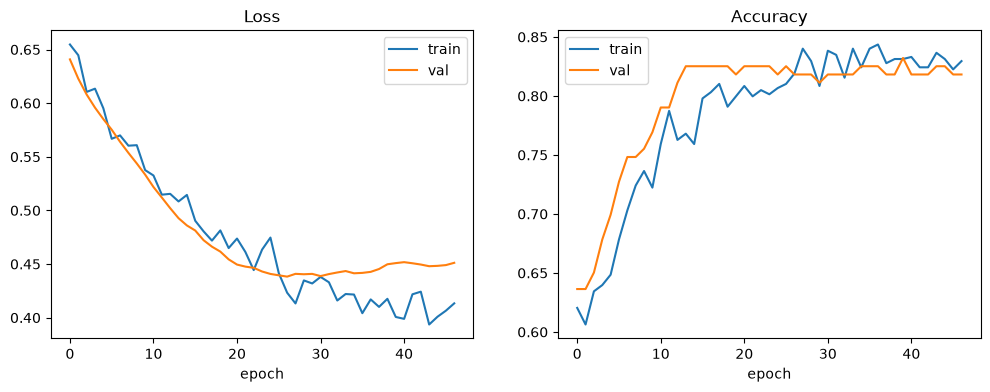

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history['loss'], label='train')
ax[0].plot(history.history['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()

ax[1].plot(history.history['accuracy'], label='train')
ax[1].plot(history.history['val_accuracy'], label='val')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()

plt.show()

In [17]:
# 확률 0.5 이상이면 생존(1)으로 예측
y_pred = (model.predict(X_te, verbose=0) >= 0.5).astype(int).ravel()

acc = accuracy_score(y_test, y_pred)
print(f"테스트 정확도: {acc:.4f}")

테스트 정확도: 0.7821
